# Section 5 — Newton's Method

[← Fixed Points and Cobwebs](04_fixed_point_cobwebs.ipynb) ·
[Module 1](README.md) ·
[Next: Order of Convergence →](06_order_of_convergence.ipynb)

Newton's method replaces the graph of $f$ by its tangent line at the current
approximation. If $p_{n-1}$ is the current approximation, then

$$
p_n
=
p_{n-1}
-
\frac{f(p_{n-1})}{f'(p_{n-1})}.
$$

### Learning goals

- derive the Newton update from a tangent line;
- implement Newton's method;
- visualize successive tangent-line approximations;
- recognize divergence, cycles, derivative problems, and slow convergence;
- compare Newton's fast local convergence with the guaranteed but slower
  bisection method.


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

## A successful example

Use Newton's method for

$$
f(x)=2-e^x
$$

with $p_0=0.5$. The exact root is $p=\ln 2$.


In [2]:
def f(x):
    return 2.0 - math.exp(x)


def derivative_f(x):
    return -math.exp(x)


def newton(
    function,
    derivative,
    p0,
    tolerance=1.0e-10,
    max_iterations=20,
):
    """Approximate a root using Newton's method."""
    p_old = p0
    history = [p_old]

    for _ in range(max_iterations):
        derivative_value = derivative(p_old)

        if derivative_value == 0:
            message = "Newton's method encountered a zero derivative."
            raise ZeroDivisionError(message)

        p_new = p_old - function(p_old) / derivative_value
        history.append(p_new)

        if abs(p_new - p_old) < tolerance:
            return p_new, history

        p_old = p_new

    return p_new, history


root, history = newton(f, derivative_f, 0.5)

print(" n          p_n")
for n, value in enumerate(history):
    print(f"{n:2d}   {value:.12f}")

print(f"\napproximate root = {root:.12f}")
print(f"exact root       = {math.log(2):.12f}")

 n          p_n
 0   0.500000000000
 1   0.713061319425
 2   0.693344157316
 3   0.693147199959
 4   0.693147180560
 5   0.693147180560

approximate root = 0.693147180560
exact root       = 0.693147180560


## Geometry of the first Newton steps

At $p_n$, draw the tangent line to $f$. Its $x$-intercept is $p_{n+1}$.


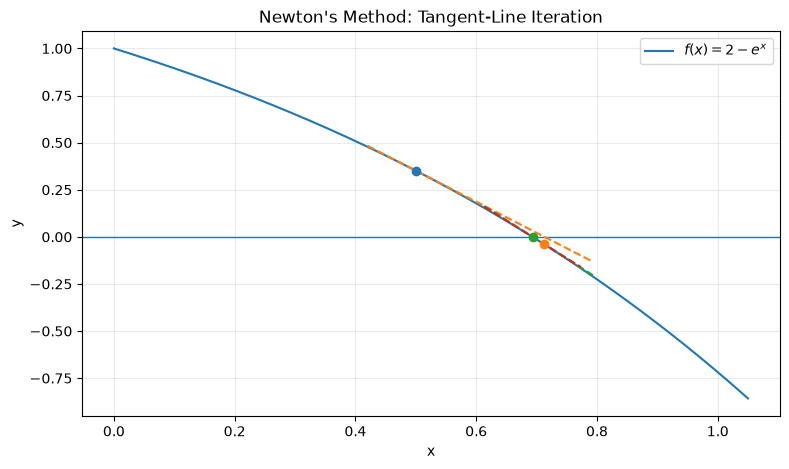

In [3]:
def f_array(x):
    return 2.0 - np.exp(x)


x_values = np.linspace(0.0, 1.05, 400)

plt.figure(figsize=(9, 5))
plt.plot(x_values, f_array(x_values), label=r"$f(x)=2-e^x$")
plt.axhline(0.0, linewidth=1)

for index in range(min(3, len(history) - 1)):
    p_old = history[index]
    p_new = history[index + 1]
    slope = derivative_f(p_old)
    left = min(p_old, p_new) - 0.08
    right = max(p_old, p_new) + 0.08
    tangent_x = np.linspace(left, right, 50)
    tangent_y = f(p_old) + slope * (tangent_x - p_old)

    plt.plot(tangent_x, tangent_y, linestyle="--")
    plt.scatter([p_old], [f(p_old)], zorder=3)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Newton's Method: Tangent-Line Iteration")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

# When Newton's Method Fails

Newton's method can converge extremely quickly, but **it is not guaranteed to
converge**. Its behavior depends on the function and the starting value.

The examples below show three different kinds of failure or degraded behavior:

1. divergence even though a root exists;
2. a cycle that never reaches the root;
3. convergence to a multiple root, but only at a linear rate.

These examples are useful because they show why a robust method such as
bisection still matters.


## Failure 1 — $f(x)=\sqrt[3]{x}$ diverges from every nonzero starting value

Consider

$$
f(x)=x^{1/3}.
$$

The equation $f(x)=0$ has the root $p=0$. For $x\neq0$,

$$
f'(x)=\frac{1}{3}x^{-2/3}.
$$

Newton's update is therefore

$$
\begin{aligned}
p_{n+1}
&=p_n-\frac{p_n^{1/3}}
{\frac{1}{3}p_n^{-2/3}}\\
&=p_n-3p_n\\
&=-2p_n.
\end{aligned}
$$

Thus

$$
p_n=(-2)^n p_0,
$$

and consequently

$$
|p_n|=2^n|p_0|\longrightarrow\infty
$$

for **every $p_0\neq0$**.

The signs alternate and the magnitude doubles at every iteration. If
$p_0=0$, the usual Newton formula is not defined because $f'(0)$ does not
exist.


In [4]:
def cube_root_newton_history(p0, iterations=8):
    """Return Newton iterates for f(x) = cube root of x."""
    values = [float(p0)]

    for _ in range(iterations):
        values.append(-2.0 * values[-1])

    return np.array(values)


starting_values = [1.0, 0.5, -0.25]

for p0 in starting_values:
    values = cube_root_newton_history(p0)
    print(f"p_0 = {p0:g}")
    for n, value in enumerate(values):
        print(f"  p_{n} = {value:10.6f}")
    print()

p_0 = 1
  p_0 =   1.000000
  p_1 =  -2.000000
  p_2 =   4.000000
  p_3 =  -8.000000
  p_4 =  16.000000
  p_5 = -32.000000
  p_6 =  64.000000
  p_7 = -128.000000
  p_8 = 256.000000

p_0 = 0.5
  p_0 =   0.500000
  p_1 =  -1.000000
  p_2 =   2.000000
  p_3 =  -4.000000
  p_4 =   8.000000
  p_5 = -16.000000
  p_6 =  32.000000
  p_7 = -64.000000
  p_8 = 128.000000

p_0 = -0.25
  p_0 =  -0.250000
  p_1 =   0.500000
  p_2 =  -1.000000
  p_3 =   2.000000
  p_4 =  -4.000000
  p_5 =   8.000000
  p_6 = -16.000000
  p_7 =  32.000000
  p_8 = -64.000000



### Numerical picture

The next plot shows the iterates themselves. They alternate across the root
while moving farther away from it.


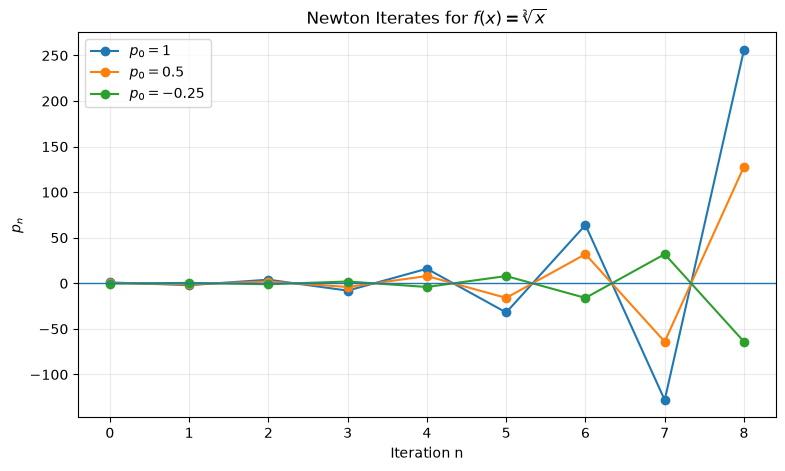

In [5]:
plt.figure(figsize=(9, 5))

for p0 in starting_values:
    values = cube_root_newton_history(p0)
    n_values = np.arange(len(values))
    plt.plot(
        n_values,
        values,
        marker="o",
        label=fr"$p_0={p0:g}$",
    )

plt.axhline(0.0, linewidth=1)
plt.xlabel("Iteration n")
plt.ylabel(r"$p_n$")
plt.title(r"Newton Iterates for $f(x)=\sqrt[3]{x}$")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

### View Newton's method as a fixed-point iteration

Every Newton method can be written as

$$
p_{n+1}=g(p_n),
\qquad
g(x)=x-\frac{f(x)}{f'(x)}.
$$

For the cube-root example,

$$
g(x)=-2x.
$$

So the Newton map is just a line of slope $-2$. The fixed point $0$ is
repelling: each trip from $y=g(x)$ to $y=x$ doubles the distance from the
origin.

This also connects Newton's method back to the cobweb diagrams from the
previous section.


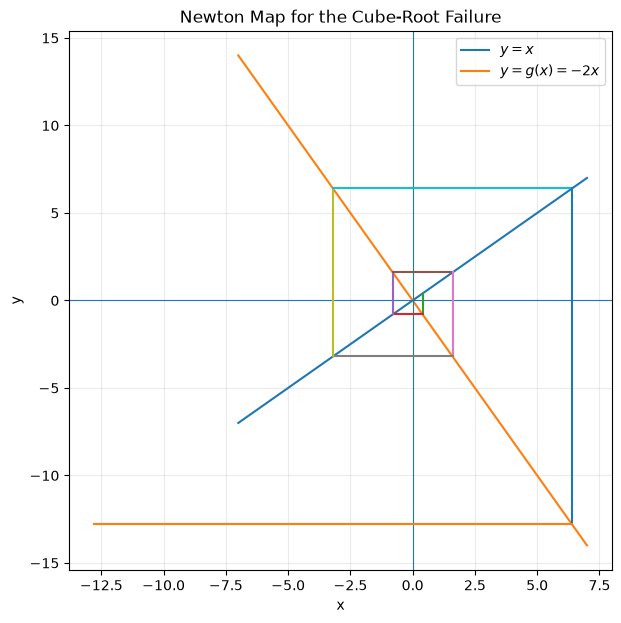

In [6]:
def plot_cube_root_newton_map(p0=0.4, iterations=5):
    """Plot the Newton map g(x) = -2x and its first cobweb steps."""
    x_values = np.linspace(-7.0, 7.0, 500)

    plt.figure(figsize=(7, 7))
    plt.plot(x_values, x_values, label=r"$y=x$")
    plt.plot(x_values, -2.0 * x_values, label=r"$y=g(x)=-2x$")
    plt.axhline(0.0, linewidth=0.8)
    plt.axvline(0.0, linewidth=0.8)

    current = p0

    for _ in range(iterations):
        next_value = -2.0 * current
        plt.plot(
            [current, current],
            [current, next_value],
            linewidth=1.5,
        )
        plt.plot(
            [current, next_value],
            [next_value, next_value],
            linewidth=1.5,
        )
        current = next_value

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Newton Map for the Cube-Root Failure")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()


plot_cube_root_newton_map()

### Geometric reason for the failure

The graph $y=\sqrt[3]{x}$ has a **vertical tangent at the root**. Away from
the root, Newton's tangent construction produces the simple update
$p_{n+1}=-2p_n$. Instead of moving toward the root, the tangent intercept
lands on the opposite side at twice the distance.

So this is not merely a poor choice of $p_0$: every nonzero initial guess
diverges.


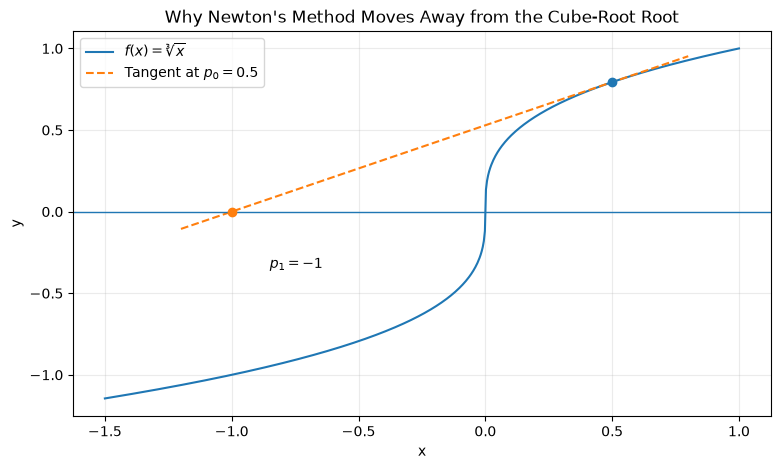

In [7]:
def cube_root(x):
    return np.cbrt(x)


def cube_root_derivative(x):
    return 1.0 / (3.0 * np.cbrt(x) ** 2)


p_old = 0.5
p_new = -2.0 * p_old

x_values = np.linspace(-1.5, 1.0, 600)
tangent_x = np.linspace(-1.2, 0.8, 200)
slope = cube_root_derivative(p_old)
tangent_y = cube_root(p_old) + slope * (tangent_x - p_old)

plt.figure(figsize=(9, 5))
plt.plot(
    x_values,
    cube_root(x_values),
    label=r"$f(x)=\sqrt[3]{x}$",
)
plt.plot(
    tangent_x,
    tangent_y,
    linestyle="--",
    label=fr"Tangent at $p_0={p_old}$",
)
plt.axhline(0.0, linewidth=1)
plt.scatter([p_old], [cube_root(p_old)], zorder=3)
plt.scatter([p_new], [0.0], zorder=3)
plt.annotate(
    fr"$p_1={p_new:g}$",
    xy=(p_new, 0.0),
    xytext=(p_new + 0.15, -0.35),
)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Why Newton's Method Moves Away from the Cube-Root Root")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## Failure 2 — Newton's method can enter a cycle

Consider

$$
f(x)=x^3-2x+2.
$$

Then

$$
f'(x)=3x^2-2.
$$

Starting from $p_0=0$,

$$
p_1
=
0-\frac{2}{-2}
=
1,
$$

and then

$$
p_2
=
1-\frac{1}{1}
=
0.
$$

The process repeats forever:

$$
0\rightarrow1\rightarrow0\rightarrow1\rightarrow\cdots
$$

The iterates do not approach a root even though the Newton formula remains
defined at both points.


In [8]:
def cycle_function(x):
    return x**3 - 2.0 * x + 2.0


def cycle_derivative(x):
    return 3.0 * x**2 - 2.0


cycle_values = [0.0]

for _ in range(8):
    current = cycle_values[-1]
    next_value = current - (
        cycle_function(current) / cycle_derivative(current)
    )
    cycle_values.append(next_value)

print(" n          p_n")
for n, value in enumerate(cycle_values):
    print(f"{n:2d}   {value:.12f}")

 n          p_n
 0   0.000000000000
 1   1.000000000000
 2   0.000000000000
 3   1.000000000000
 4   0.000000000000
 5   1.000000000000
 6   0.000000000000
 7   1.000000000000
 8   0.000000000000


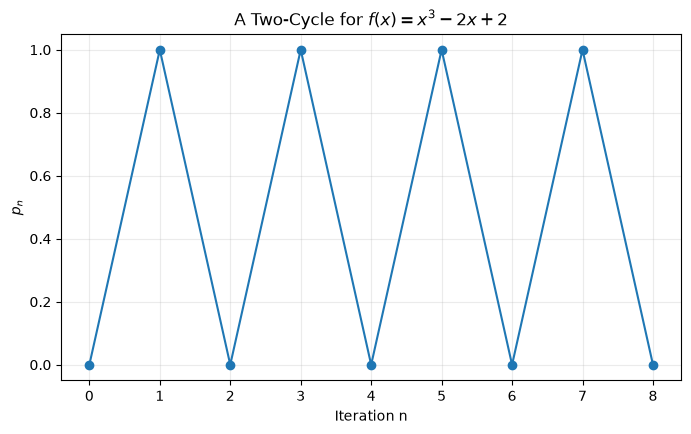

In [9]:
n_values = np.arange(len(cycle_values))

plt.figure(figsize=(8, 4.5))
plt.plot(n_values, cycle_values, marker="o")
plt.xlabel("Iteration n")
plt.ylabel(r"$p_n$")
plt.title(r"A Two-Cycle for $f(x)=x^3-2x+2$")
plt.grid(alpha=0.25)
plt.show()

## Degraded behavior — a multiple root can destroy quadratic convergence

Newton's method is usually quadratically convergent near a **simple** root.
That conclusion can fail at a multiple root.

For

$$
f(x)=(x-1)^2,
$$

the root $p=1$ has multiplicity two. Newton's method becomes

$$
\begin{aligned}
p_{n+1}
&=p_n-\frac{(p_n-1)^2}{2(p_n-1)}\\
&=\frac{p_n+1}{2}.
\end{aligned}
$$

Therefore

$$
|p_{n+1}-1|
=
\frac{1}{2}|p_n-1|.
$$

The method still converges, but only **linearly**, with asymptotic error
constant $1/2$.


In [10]:
def multiple_root_function(x):
    return (x - 1.0) ** 2


def multiple_root_derivative(x):
    return 2.0 * (x - 1.0)


_, multiple_history = newton(
    multiple_root_function,
    multiple_root_derivative,
    4.0,
    tolerance=1.0e-12,
    max_iterations=12,
)

print(" n          p_n             error")
for n, value in enumerate(multiple_history):
    error = abs(value - 1.0)
    print(f"{n:2d}   {value:14.10f}   {error:.10e}")

 n          p_n             error
 0     4.0000000000   3.0000000000e+00
 1     2.5000000000   1.5000000000e+00
 2     1.7500000000   7.5000000000e-01
 3     1.3750000000   3.7500000000e-01
 4     1.1875000000   1.8750000000e-01
 5     1.0937500000   9.3750000000e-02
 6     1.0468750000   4.6875000000e-02
 7     1.0234375000   2.3437500000e-02
 8     1.0117187500   1.1718750000e-02
 9     1.0058593750   5.8593750000e-03
10     1.0029296875   2.9296875000e-03
11     1.0014648438   1.4648437500e-03
12     1.0007324219   7.3242187500e-04


## What to remember

Newton's method is powerful, but the theorem-like slogan

> “Newton's method converges quadratically”

requires hypotheses.

Before trusting the iteration, ask:

- Is $f'$ defined near the root?
- Can $f'(p_n)$ become zero or very small?
- Is the starting value close enough to the desired root?
- Does the Newton iteration map attract or repel nearby points?
- Is the root simple or multiple?

The cube-root example is especially important:

$$
f(x)=\sqrt[3]{x}
\quad\Longrightarrow\quad
p_{n+1}=-2p_n.
$$

Hence Newton's method diverges for **every nonzero initial guess**, even
though the root $p=0$ is obvious.

This is one reason bisection remains useful: when its hypotheses hold,
bisection keeps a root bracketed and converges regardless of these Newton
failure modes.


### References

- Leon Q. Brin, *Tea Time Numerical Analysis*.
- Richard L. Burden and J. Douglas Faires, *Numerical Analysis*.

[← Fixed Points and Cobwebs](04_fixed_point_cobwebs.ipynb) ·
[Next: Order of Convergence →](06_order_of_convergence.ipynb)
